# 04 · Preprocesamiento sin fugas de información

**Objetivo:** transformar el dataset en entradas válidas para una red recurrente cumpliendo las tres reglas del enunciado (limpieza, normalización ajustada solo con train, secuencias de 60 días) y **garantizando que ningún dato del futuro se filtra al entrenamiento**.

Pasos:
1. Punto de partida: dataset limpio (notebook 01) y variables seleccionadas (notebook 03).
2. Tratamiento de *outliers* en las entradas.
3. Variable objetivo por horizonte.
4. Particiones temporales: walk-forward con embargo + test final.
5. Escalado por fold.
6. Creación de secuencias.

Todo el código reutilizable está en `src/oil_forecast/`; este notebook lo aplica y lo verifica.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_forecast.config import HORIZONS, TARGET, TEST_START, VAL_YEARS, WINDOW
from oil_forecast.data import load_dataset, log_return_targets
from oil_forecast.features import SELECTED_FEATURES, FoldScaler, build_features
from oil_forecast.sequences import make_sequences
from oil_forecast.splits import train_test_split, walk_forward_folds
from oil_forecast.plotting import set_style

set_style()
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Punto de partida

- `data/petroleo_dataset.csv`, generado por el ETL (notebook 01): solo días con cotización **real** del Brent; las variables externas con su último valor conocido, nunca rellenadas hacia atrás.

In [2]:
df = load_dataset()
print(f"{len(df):,} días · {df.index.min():%d/%m/%Y} - {df.index.max():%d/%m/%Y}")

6,501 días · 04/01/2000 - 03/11/2026


## 2. Variables de entrada

Las 16 variables elegidas en el notebook 03 (`features.SELECTED_FEATURES`), todas calculadas con información disponible al cierre del día *t*:

| Grupo | Variables |
|---|---|
| Retornos diarios | Brent, futuro WTI, futuro gas, oro, cobre, índice dólar, yuan |
| Régimen | volatilidad 21 y 63 días, caída desde el máximo anual |
| Estructura y valor relativo | diferencial Brent-WTI, *basis* del WTI, ratios cobre/Brent y oro/Brent |
| Riesgo y política monetaria | log VIX, cambio trimestral del tipo del BCE |

**Outliers:** el WTI negativo (20/04/2020) hace que su logaritmo no exista → en las variables que lo usan se toma el valor del día anterior. El resto de extremos (2008, 2020, 2022, 2026) **no se eliminan** (son la realidad que el modelo debe soportar), pero las entradas se **winsorizan** con los cuantiles 0,5 % y 99,5 % del train de cada fold. La variable objetivo nunca se recorta.

In [3]:
feats = build_features(df)
assert list(feats.columns) == SELECTED_FEATURES
print(f"Primera fecha con todas las variables disponibles: {feats.index[0]:%d/%m/%Y} (ventanas de 252 días sobre series de Yahoo que empiezan en 08/2000)")
print(f"Matriz de entrada: {feats.shape[0]:,} días × {feats.shape[1]} variables")
feats.describe().T[["mean", "std", "min", "max"]]

Primera fecha con todas las variables disponibles: 11/12/2001 (ventanas de 252 días sobre series de Yahoo que empiezan en 08/2000)
Matriz de entrada: 6,113 días × 16 variables


,mean,std,min,max
ret_brent,0.000,0.027,-0.644,0.412
ret_wti_fut,0.000,0.026,-0.282,0.320
ret_gas_fut,0.000,0.038,-0.644,0.382
ret_oro,0.000,0.012,-0.114,0.086
ret_cobre,0.000,0.018,-0.252,0.124
ret_indice_dolar,-0.000,0.005,-0.027,0.025
ret_cny_por_usd,-0.000,0.002,-0.020,0.018
vol_21,0.022,0.015,0.005,0.216
vol_63,0.023,0.014,0.007,0.140
drawdown_252,-0.232,0.251,-2.103,0.000


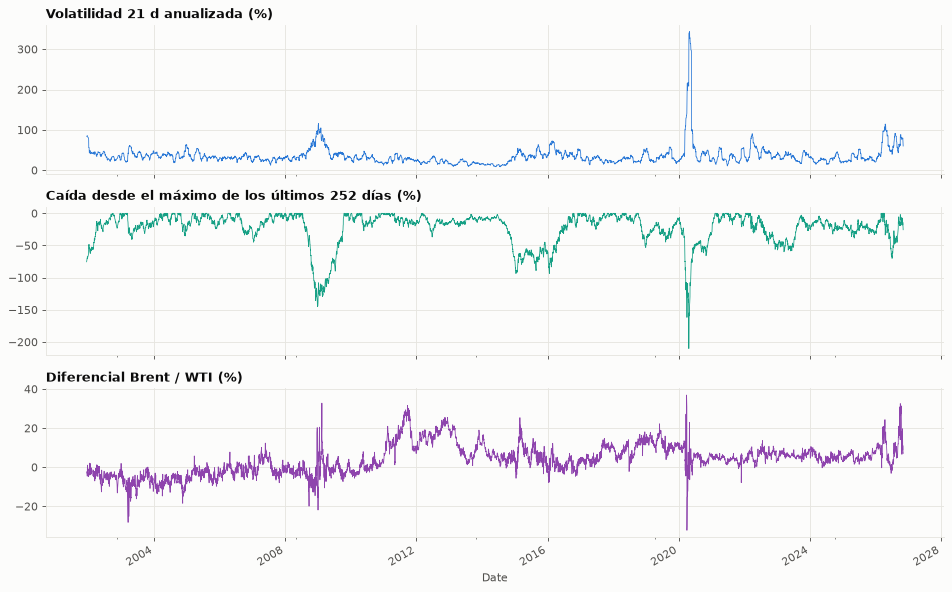

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
feats["vol_21"].mul(np.sqrt(252) * 100).plot(ax=axes[0], lw=0.7, title="Volatilidad 21 d anualizada (%)")
feats["drawdown_252"].mul(100).plot(ax=axes[1], lw=0.7, color="#16a085", title="Caída desde el máximo de los últimos 252 días (%)")
feats["spread_brent_wti"].mul(100).plot(ax=axes[2], lw=0.7, color="#8e44ad", title="Diferencial Brent / WTI (%)")
plt.tight_layout()

## 3. Variable objetivo

Para cada horizonte *h* ∈ {5, 63, 252} se predice el **retorno logarítmico acumulado** $y_h(t) = \ln(P_{t+h}/P_t)$ y el precio se reconstruye como $\hat P_{t+h} = P_t\, e^{\hat y}$.

- Es estacionario (el precio no) y no depende del nivel → el escalador no se "sale de rango" con precios nunca vistos.
- El modelo ingenuo es exactamente $\hat y = 0$.
- Los últimos *h* días no tienen objetivo conocido: son precisamente los días desde los que la app hace la predicción real.

In [5]:
targets = log_return_targets(df[TARGET], HORIZONS).loc[feats.index]
data = feats.join(targets)
data.filter(like="y_").tail(3)

,ret_cny_por_usd,y_5,y_63,y_252
Date,,,,
2026-10-30,-0.001,NaN,NaN,NaN
2026-11-02,0.000,NaN,NaN,NaN
2026-11-03,0.000,NaN,NaN,NaN


## 4. Particiones temporales (idénticas para RNN, LSTM y GRU)

- **Test final (hold-out):** orígenes desde el **01/01/2024**. No se usa para entrenar ni para elegir hiperparámetros. Incluye la crisis de Ormuz de 2026.
- **Walk-forward para el ajuste:** ventana de entrenamiento **expansiva** y un bloque de validación por año (2019-2023).
- **Embargo de *h* días:** los objetivos se solapan (dos retornos a 252 días consecutivos comparten 251 días). Si el último origen de train fuese el día anterior a la validación, su objetivo contendría precios del periodo de validación → fuga. Por eso se eliminan los últimos *h* orígenes antes de cada bloque, y en el último bloque se descartan los orígenes cuyo objetivo cae ya en el test.

In [6]:
index = data.index
rows = []
for name, h in HORIZONS.items():
    for f in walk_forward_folds(index, h, VAL_YEARS, TEST_START):
        rows.append({"horizonte": name, "fold": f.name, "train": f"{index[f.train[0]]:%Y-%m-%d} → {index[f.train[-1]]:%Y-%m-%d}",
                     "n_train": len(f.train), "validación": f"{index[f.val[0]]:%Y-%m-%d} → {index[f.val[-1]]:%Y-%m-%d}",
                     "n_val": len(f.val)})
    tr, te = train_test_split(index, h, TEST_START)
    rows.append({"horizonte": name, "fold": "TEST", "train": f"{index[tr[0]]:%Y-%m-%d} → {index[tr[-1]]:%Y-%m-%d}",
                 "n_train": len(tr), "validación": f"{index[te[0]]:%Y-%m-%d} → {index[te[-1]]:%Y-%m-%d}", "n_val": len(te)})
splits = pd.DataFrame(rows)
splits

,horizonte,fold,train,n_train,validación,n_val
0,corto,2019,2001-12-11 → 2018-12-18,4120,2019-01-02 → 2019-12-31,257
1,corto,2020,2001-12-11 → 2019-12-23,4377,2020-01-02 → 2020-12-31,255
2,corto,2021,2001-12-11 → 2020-12-23,4632,2021-01-04 → 2021-12-31,253
3,corto,2022,2001-12-11 → 2021-12-22,4885,2022-01-03 → 2022-12-30,252
4,corto,2023,2001-12-11 → 2022-12-21,5137,2023-01-03 → 2023-12-20,246
5,corto,TEST,2001-12-11 → 2023-12-20,5388,2024-01-02 → 2026-10-27,715
6,medio,2019,2001-12-11 → 2018-09-27,4062,2019-01-02 → 2019-12-31,257
7,medio,2020,2001-12-11 → 2019-10-02,4319,2020-01-02 → 2020-12-31,255
8,medio,2021,2001-12-11 → 2020-10-02,4574,2021-01-04 → 2021-12-31,253
9,medio,2022,2001-12-11 → 2021-10-01,4827,2022-01-03 → 2022-12-30,252


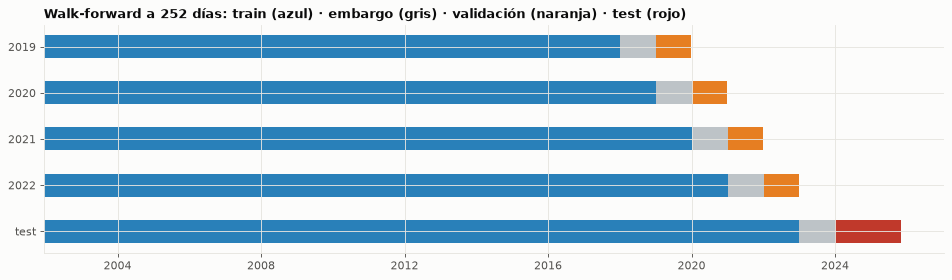

In [7]:
h = HORIZONS["largo"]
fig, ax = plt.subplots(figsize=(12, 3.6))
folds = walk_forward_folds(index, h, VAL_YEARS, TEST_START)
tr, te = train_test_split(index, h, TEST_START)
blocks = [(f.name, f.train, f.val) for f in folds] + [("test", tr, te)]
for i, (name, train, val) in enumerate(blocks):
    ax.barh(i, index[train[-1]] - index[train[0]], left=index[train[0]], color="#2980b9", height=0.5)
    ax.barh(i, index[val[0]] - index[train[-1]], left=index[train[-1]], color="#bdc3c7", height=0.5)
    ax.barh(i, index[val[-1]] - index[val[0]], left=index[val[0]], color="#e67e22" if name != "test" else "#c0392b", height=0.5)
ax.set_yticks(range(len(blocks)), [b[0] for b in blocks]); ax.invert_yaxis()
ax.set_title("Walk-forward a 252 días: train (azul) · embargo (gris) · validación (naranja) · test (rojo)")
plt.tight_layout()

## 5. Escalado ajustado solo con train

El `FoldScaler` aprende los cuantiles de winsorización, la media y la desviación **solo con las filas de entrenamiento del fold** y aplica esa misma transformación a validación/test. Comparamos con lo que pasaría si se ajustase con todo el histórico (error habitual).

In [8]:
fold = walk_forward_folds(index, HORIZONS["medio"], VAL_YEARS, TEST_START)[0]
X_cols = feats.columns
scaler = FoldScaler().fit(data.iloc[fold.train][X_cols])
leaky = FoldScaler().fit(data[X_cols])
comp = pd.DataFrame({"media train": scaler.mean_, "media todo (fuga)": leaky.mean_,
                     "desv. train": scaler.std_, "desv. todo (fuga)": leaky.std_})
comp.loc[["log_vix", "vol_21", "spread_brent_wti", "ratio_cobre_z252", "ret_brent"]]

,media train,media todo (fuga),desv. train,desv. todo (fuga)
log_vix,2.866,2.892,0.375,0.351
vol_21,0.020,0.022,0.009,0.013
spread_brent_wti,0.028,0.042,0.082,0.075
ratio_cobre_z252,0.026,0.072,1.310,1.321
ret_brent,0.000,0.000,0.021,0.023


In [9]:
Z_val = scaler.transform(data.iloc[fold.val][X_cols])
print(f"Fold {fold.name}: validación escalada con estadísticos de train → media {Z_val.mean().mean():+.2f}, desv. {Z_val.std().mean():.2f}")
print("(No tiene por qué ser 0/1: la validación es un periodo distinto. Que no lo sea es justamente la prueba de que no hay fuga.)")

Fold 2019: validación escalada con estadísticos de train → media +0.11, desv. 0.63
(No tiene por qué ser 0/1: la validación es un periodo distinto. Que no lo sea es justamente la prueba de que no hay fuga.)


Las medias y desviaciones cambian al incluir el futuro (por ejemplo la volatilidad y el VIX, por 2020 y 2022): si el escalador viera todo el histórico, el modelo "sabría" durante el entrenamiento cómo es el periodo que se va a evaluar.

## 6. Secuencias de 60 días

In [10]:
X = scaler.transform(data[X_cols]).to_numpy(dtype="float32")
y = data[f"y_{HORIZONS['medio']}"].to_numpy(dtype="float32")
X_tr, y_tr = make_sequences(X, y, fold.train, WINDOW)
X_va, y_va = make_sequences(X, y, fold.val, WINDOW)
print(f"Train: X {X_tr.shape}, y {y_tr.shape}")
print(f"Val:   X {X_va.shape}, y {y_va.shape}")
print("Formato (muestras, pasos de tiempo, variables) → entrada directa a SimpleRNN / LSTM / GRU")

Train: X (4003, 60, 16), y (4003,)
Val:   X (257, 60, 16), y (257,)
Formato (muestras, pasos de tiempo, variables) → entrada directa a SimpleRNN / LSTM / GRU


In [11]:
t = fold.val[0]
print(f"Ejemplo — origen t = {index[t]:%d/%m/%Y}")
print(f"  entrada: {index[t - WINDOW + 1]:%d/%m/%Y} → {index[t]:%d/%m/%Y} ({WINDOW} días)")
print(f"  objetivo: retorno del Brent hasta {index[t + HORIZONS['medio']]:%d/%m/%Y} = {y[t]:+.3%}")
print(f"  último origen de train: {index[fold.train[-1]]:%d/%m/%Y}, su objetivo termina el {index[fold.train[-1] + HORIZONS['medio']]:%d/%m/%Y} (< inicio de validación)")

Ejemplo — origen t = 02/01/2019
  entrada: 04/10/2018 → 02/01/2019 (60 días)
  objetivo: retorno del Brent hasta 01/04/2019 = +24.517%
  último origen de train: 27/09/2018, su objetivo termina el 28/12/2018 (< inicio de validación)


## Resumen

- Entradas: las 16 variables seleccionadas en el notebook 03, desde diciembre de 2001.
- Objetivo por horizonte en retornos log acumulados.
- Particiones idénticas para las tres redes, con embargo y test intocable desde 2024.
- Escalado y winsorización ajustados por fold solo con train.
- Secuencias `(n, 60, n_variables)` listas para las redes.

Las garantías anti-fuga están cubiertas por tests automáticos en `tests/test_no_leakage.py`.